In [4]:

import numpy as np
import matplotlib.pyplot as plt

K = 3

n = 10000 

# class 1
mu1 =  [
    [1, 0],
    [1, 5],
    [1, 10]
]

#Class 2
mu2 = [
    [9, 0],
    [9, 5],
    [9, 10]
]

# Mixture weights
pi1 = [0.3, 0.4, 0.3]
pi2 = [0.2, 0.5, 0.3]



In [5]:

from math import log,sqrt,cos,sin,pi

seed=42
# Linear Congruential Generator (LCG)
def random_number():
    global seed
    seed=(1664525*seed+1013904223)%(2**32)
    return seed/(2**32)
    
# Box-Muller Transform
def box_muller():
    u1=random_number()
    u2=random_number()
    while u1==0:
        u1=random_number()
    z1=sqrt(-2*log(u1))*cos(2*pi*u2)
    z2=sqrt(-2*log(u1))*sin(2*pi*u2)
    return np.array([z1,z2])


In [6]:

# Spherical covariance
C_spherical = np.array([
    [4, 0],
    [0, 4]
])

# Diagonal covariance
C_diagonal = np.array([
    [4, 0],
    [0, 1]
])

# Full covariance
C_full = np.array([
    [4, 2],
    [2, 3]
])


In [7]:
# Generate a uniform random number between 0 and 1

def select_component(weights):
    r = random_number()

    if r < weights[0]:
        return 0
    elif weights[0] < r < weights[0] + weights[1]:
        return 1
    else:
        return 2






In [8]:

def covariance_transform(C):
    a = np.sqrt(C[0, 0])
    b = C[1, 0] / a
    c = np.sqrt(C[1, 1] - b * b)

    return np.array([
        [a, 0],
        [b, c]
    ])


def generate_data(means, weights, C, n):
    data = []
    components = []

    A = covariance_transform(C)

    for i in range(n):
        k = select_component(weights)

        z = box_muller()

        x=np.array(means[k])+np.dot(A,z)
        data.append(x)
        components.append(k)

    return np.array(data), np.array(components)


# Generate spherical covariance data
X1, labels1 = generate_data(mu1, pi1, C_spherical, n)
X2, labels2 = generate_data(mu2, pi2, C_spherical, n)

print("Class 1 Data Shape:", X1.shape)
print("Class 2 Data Shape:", X2.shape)


Class 1 Data Shape: (10000, 2)
Class 2 Data Shape: (10000, 2)


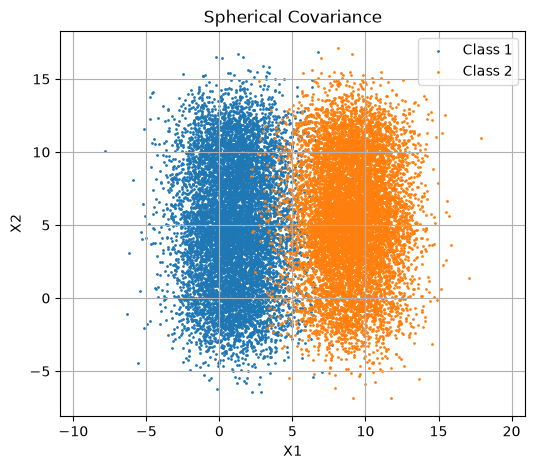

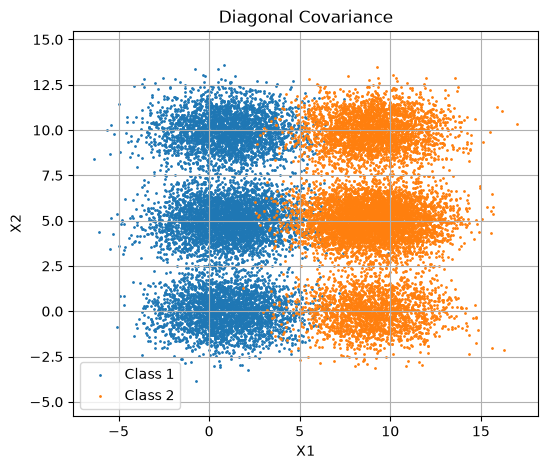

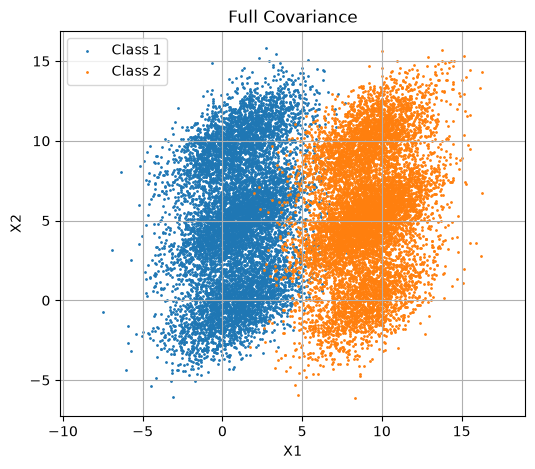

In [9]:

covariances = [
    ("Spherical Covariance", C_spherical),
    ("Diagonal Covariance", C_diagonal),
    ("Full Covariance", C_full)
]

for title, C in covariances:

    X1, labels1 = generate_data(mu1, pi1, C, n)
    X2, labels2 = generate_data(mu2, pi2, C, n)

    plt.figure(figsize=(6,5))

    plt.scatter(X1[:, 0], X1[:, 1],
                s=1, 
                label="Class 1")

    plt.scatter(X2[:, 0], X2[:, 1],
                s=1, 
                label="Class 2")

    plt.title(title)
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.legend()
    plt.grid(True)
    plt.axis("equal")
    plt.show()


In [10]:
def split_data(X):
    X = X.copy()
    n = len(X)

    for i in range(n - 1, 0, -1):
        j = int(random_number() * (i + 1))
        X[i], X[j] = X[j].copy(), X[i].copy()

    n_train = int(0.8 * n)

    train = X[:n_train]
    test = X[n_train:]

    return train, test


# Generate and split data for all covariance types
datasets = {}

for name, C in covariances:

    X1, labels1 = generate_data(mu1, pi1, C, n)
    X2, labels2 = generate_data(mu2, pi2, C, n)

    train1, test1 = split_data(X1)
    train2, test2 = split_data(X2)

    datasets[name] = {
        "train1": train1,
        "test1": test1,
        "train2": train2,
        "test2": test2
    }

    print("\n", name)
    print("Class 1 Training:", train1.shape)
    print("Class 1 Testing:", test1.shape)
    print("Class 2 Training:", train2.shape)
    print("Class 2 Testing:", test2.shape)



 Spherical Covariance
Class 1 Training: (8000, 2)
Class 1 Testing: (2000, 2)
Class 2 Training: (8000, 2)
Class 2 Testing: (2000, 2)

 Diagonal Covariance
Class 1 Training: (8000, 2)
Class 1 Testing: (2000, 2)
Class 2 Training: (8000, 2)
Class 2 Testing: (2000, 2)

 Full Covariance
Class 1 Training: (8000, 2)
Class 1 Testing: (2000, 2)
Class 2 Training: (8000, 2)
Class 2 Testing: (2000, 2)


In [11]:

def kmeans(X, K=3, max_iter=100):

    #Select K random points as centroids
 
    index=[]
    while len(index)<K:
        j=int(random_number()*len(X))
        if j not in index:
            index.append(j)
    centroids=X[index].copy()
    for i in range(max_iter):

        #  Calculate distance from each point to centroids
        distances = np.zeros((len(X), K))

        for j in range(K):
            distances[:, j] = np.sum(
                (X - centroids[j]) ** 2, axis=1
            )

        # Assign each point to nearest centroid
        labels = np.argmin(distances, axis=1)

        # Calculate new centroids
        new_centroids = centroids.copy()

        for j in range(K):
            points = X[labels == j]

            if len(points) > 0:
                new_centroids[j] = np.mean(points, axis=0)

        # Check convergence
        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return centroids, labels


# Perform K-Means for all covariance types
for name in datasets:

    train1 = datasets[name]["train1"]
    train2 = datasets[name]["train2"]

    centroids1, labels1 = kmeans(train1)
    centroids2, labels2 = kmeans(train2)

    datasets[name]["centroids1"] = centroids1
    datasets[name]["centroids2"] = centroids2

    datasets[name]["labels1"] = labels1
    datasets[name]["labels2"] = labels2

    print("\n", name)
    print("Class 1 Centroids:")
    print(centroids1)

    print("Class 2 Centroids:")
    print(centroids2)



 Spherical Covariance
Class 1 Centroids:
[[ 1.04907508 -0.13568358]
 [ 1.01712412  5.05202655]
 [ 1.05241941 10.20450528]]
Class 2 Centroids:
[[ 9.09115113  5.14801853]
 [ 8.95760344 10.16104877]
 [ 8.97921272  0.06111056]]

 Diagonal Covariance
Class 1 Centroids:
[[ 0.973615    5.01933418]
 [ 0.98186458 -0.02159285]
 [ 1.11209667 10.00076522]]
Class 2 Centroids:
[[ 8.99786668e+00  5.01196809e+00]
 [ 8.99897002e+00  9.99311651e+00]
 [ 8.95298828e+00 -5.65493686e-03]]

 Full Covariance
Class 1 Centroids:
[[ 1.05963306  4.86875393]
 [ 0.46963311 -0.1411996 ]
 [ 1.48066299 10.01710849]]
Class 2 Centroids:
[[ 8.27068957  0.27108365]
 [ 9.01201418  5.16629981]
 [ 9.53397277 10.05802172]]


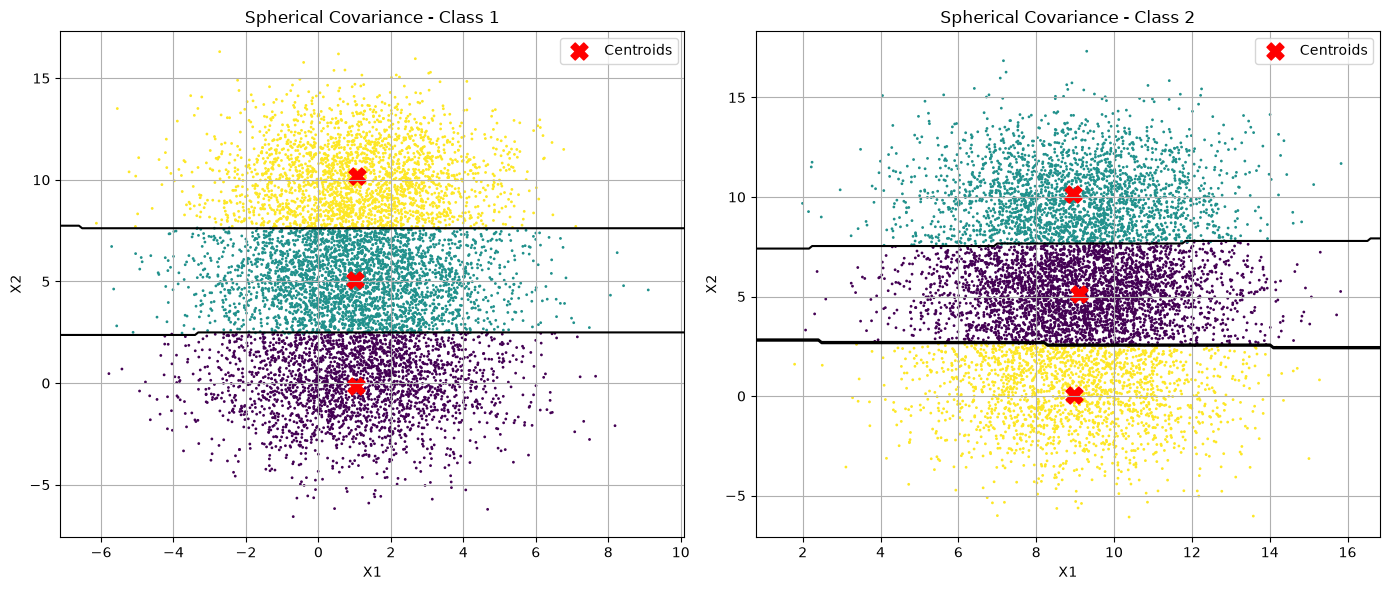

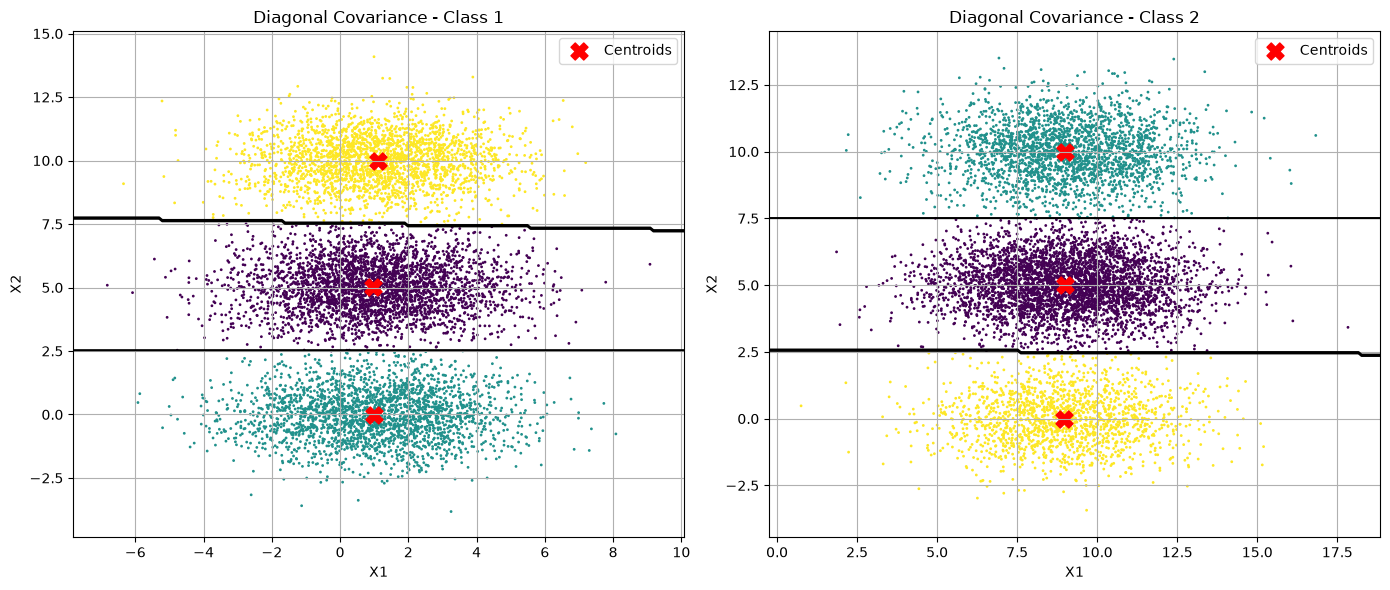

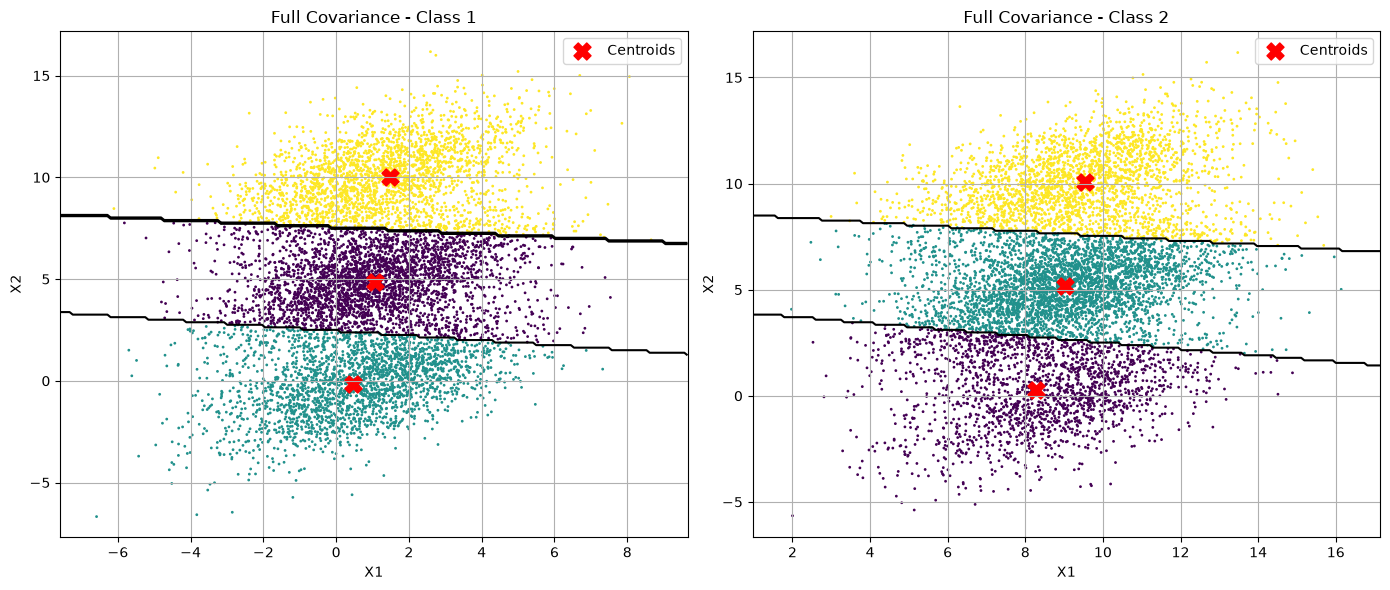

In [12]:
for name in datasets:
    fig,axes=plt.subplots(1,2,figsize=(14,6))

    for i,ax in enumerate(axes,start=1):
        X=datasets[name]["train"+str(i)]
        centroids=datasets[name]["centroids"+str(i)]
        labels=datasets[name]["labels"+str(i)]

        ax.scatter(X[:,0],X[:,1],c=labels,cmap="viridis",s=1)
        ax.scatter(centroids[:,0],centroids[:,1],c="red",marker="X",s=150,label="Centroids")

        x=np.linspace(X[:,0].min()-1,X[:,0].max()+1,200)
        y=np.linspace(X[:,1].min()-1,X[:,1].max()+1,200)
        xx,yy=np.meshgrid(x,y)
        grid=np.c_[xx.ravel(),yy.ravel()]

        distances=np.zeros((len(grid),len(centroids)))

        for j in range(len(centroids)):
            distances[:,j]=np.sum((grid-centroids[j])**2,axis=1)

        regions=np.argmin(distances,axis=1).reshape(xx.shape)
        ax.contour(xx,yy,regions,levels=[0.5,1.5],colors="black")

        ax.set_title(name+" - Class "+str(i))
        ax.set_xlabel("X1")
        ax.set_ylabel("X2")
        ax.legend()
        ax.grid(True)

    plt.tight_layout()
    plt.show()

In [13]:

def classify(X, centroids1, centroids2):
    predictions = []

    for x in X:
        # Distortion from Class 1 centroids
        d1 = np.sum((centroids1 - x) ** 2, axis=1)
        min_d1 = np.min(d1)

        # Distortion from Class 2 centroids
        d2 = np.sum((centroids2 - x) ** 2, axis=1)
        min_d2 = np.min(d2)

        # Predict the class
        if min_d1 < min_d2:
            predictions.append(1)
        else:
            predictions.append(2)

    return np.array(predictions)


# Classification and accuracy for all covariance types
for name in datasets:
    test1 = datasets[name]["test1"]
    test2 = datasets[name]["test2"]

    centroids1 = datasets[name]["centroids1"]
    centroids2 = datasets[name]["centroids2"]

    # Combine testing datasets
    X_test = np.vstack((test1, test2))

    # Actual class labels
    y_test = np.array([1] * len(test1) + [2] * len(test2))

    y_pred = classify(X_test, centroids1, centroids2)

    # Calculate correct predictions and accuracy
    correct = np.sum(y_test == y_pred)
    total = len(y_test)
    accuracy = (correct / total) * 100

    # Store results
    datasets[name]["X_test"] = X_test
    
    datasets[name]["y_test"] = y_test
    datasets[name]["y_pred"] = y_pred
    datasets[name]["correct"] = correct
    datasets[name]["accuracy"] = accuracy

    # Result
    print(f"\n  Covariance : {name}")
    print("Total Test Points:", total)
    print("Correct Predictions:", correct)
    print("Accuracy:", round(accuracy, 2), "%")


  Covariance : Spherical Covariance
Total Test Points: 4000
Correct Predictions: 3911
Accuracy: 97.78 %

  Covariance : Diagonal Covariance
Total Test Points: 4000
Correct Predictions: 3912
Accuracy: 97.8 %

  Covariance : Full Covariance
Total Test Points: 4000
Correct Predictions: 3918
Accuracy: 97.95 %


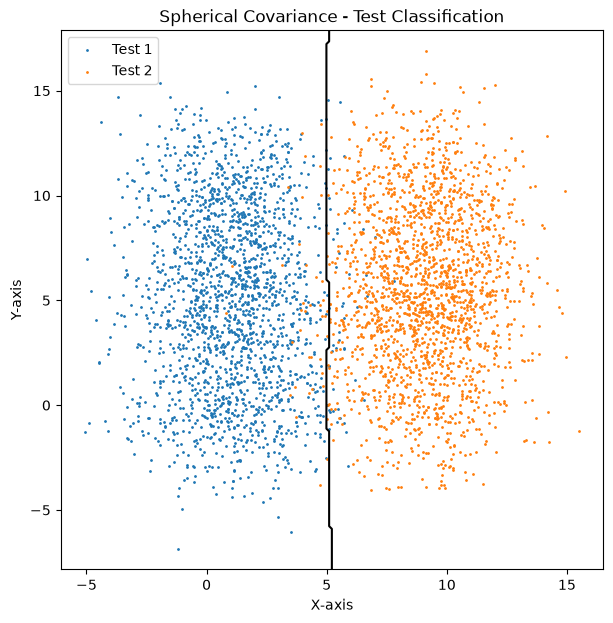

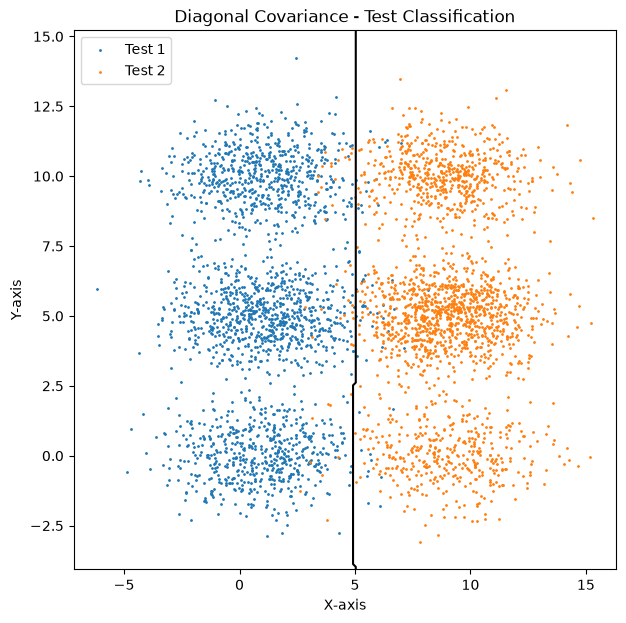

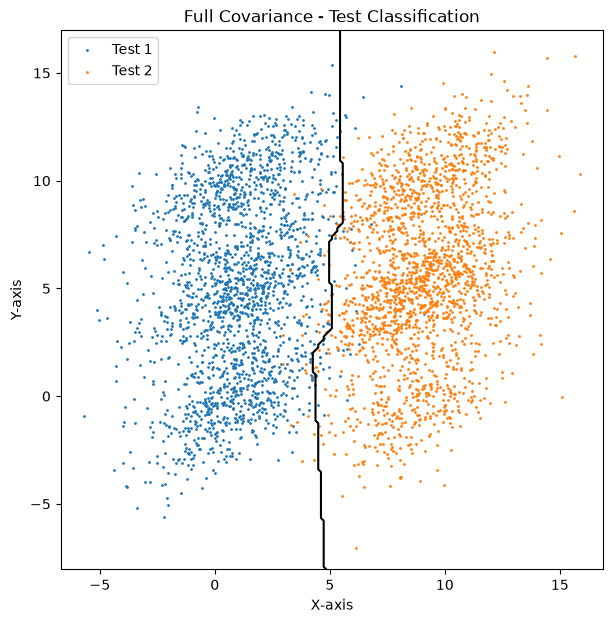

In [14]:
for name in datasets:
    test1 = datasets[name]["test1"]
    test2 = datasets[name]["test2"]
    centroids1 = datasets[name]["centroids1"]
    centroids2 = datasets[name]["centroids2"]

    X = np.vstack((test1, test2))
    x = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200)
    y = np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200)
    xx, yy = np.meshgrid(x, y)
    grid = np.c_[xx.ravel(), yy.ravel()]

    decision = classify(grid, centroids1, centroids2)
    decision = decision.reshape(xx.shape)

    plt.figure(figsize=(7, 7), facecolor="white")
    ax = plt.gca()
    ax.set_facecolor("white")

    plt.contourf(
        xx, yy, decision,
        levels=[0.5, 1.5, 2.5],
        colors=["white", "white"]
    )

    plt.contour(
        xx, yy, decision,
        levels=[1.5],
        colors="black",
        linewidths=1.5
    )

    plt.scatter(np.array(test1)[:, 0], np.array(test1)[:, 1],
                s=1, label="Test 1")
    
    plt.scatter(np.array(test2)[:, 0], np.array(test2)[:, 1],
                s=1, label="Test 2")
    
    plt.title(f"{name} - Test Classification")
    plt.xlabel("X-axis")
    plt.ylabel("Y-axis")
    
    ax.legend(loc="upper left")

    
    plt.grid(False)
    plt.show()


Spherical Covariance
Class 1 Training: (8000, 2)
Class 1 Testing: (2000, 2)
Class 2 Training: (8000, 2)
Class 2 Testing: (2000, 2)

Confusion Matrix:
[[1952   48]
 [  40 1960]]
Accuracy: 97.8 %


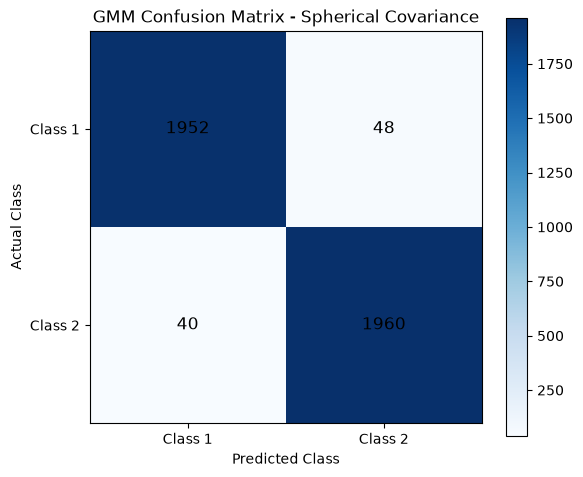


Diagonal Covariance
Class 1 Training: (8000, 2)
Class 1 Testing: (2000, 2)
Class 2 Training: (8000, 2)
Class 2 Testing: (2000, 2)

Confusion Matrix:
[[1976   24]
 [  45 1955]]
Accuracy: 98.28 %


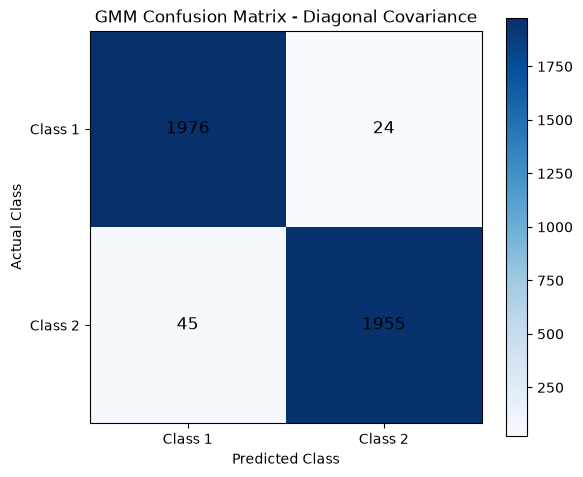


Full Covariance
Class 1 Training: (8000, 2)
Class 1 Testing: (2000, 2)
Class 2 Training: (8000, 2)
Class 2 Testing: (2000, 2)

Confusion Matrix:
[[1962   38]
 [  31 1969]]
Accuracy: 98.28 %


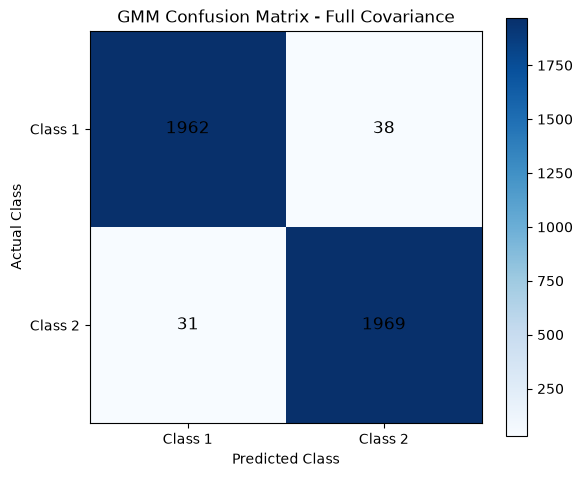

In [15]:
def generate_data(means,weights,C,n):
    data=[]
    A=covariance_transform(C)

    for _ in range(n):
        k=select_component(weights)
        z=box_muller()
        x=np.array(means[k])+A@z
        data.append(x)

    return np.array(data)


def split_data(X):
    X=np.asarray(X).copy()

    n_train=int(0.8*len(X))

    for i in range(len(X)-1,0,-1):
        j=int(random_number()*(i+1))
        X[i],X[j]=X[j].copy(),X[i].copy()

    return X[:n_train],X[n_train:]

# Train GMM using EM
def gmm_train(X,K=3,iterations=100):
    n,d=X.shape
    means=X[np.linspace(0,n-1,K,dtype=int)].copy()
    covs=np.array([np.cov(X.T)+np.eye(d)*1e-5 for _ in range(K)])
    weights=np.ones(K)/K

    for _ in range(iterations):
        log_prob=np.zeros((n,K))

        for k in range(K):
            diff=X-means[k]
            inv=np.linalg.inv(covs[k])
            _,ld=np.linalg.slogdet(covs[k])
            log_prob[:,k]=np.log(weights[k])-0.5*(
                d*np.log(2*np.pi)+ld+
                np.sum((diff@inv)*diff,axis=1)
            )

        log_prob-=np.max(log_prob,axis=1,keepdims=True)
        prob=np.exp(log_prob)
        prob/=np.sum(prob,axis=1,keepdims=True)

        nk=np.sum(prob,axis=0)+1e-10
        weights=nk/n
        means=(prob.T@X)/nk[:,None]

        for k in range(K):
            diff=X-means[k]
            covs[k]=(diff.T*prob[:,k])@diff/nk[k]
            covs[k]+=np.eye(d)*1e-5

    return means,covs,weights

# Calculate GMM log-likelihood
def gmm_score(X,model):
    means,covs,weights=model
    n,d=X.shape
    log_prob=np.zeros((n,len(weights)))

    for k in range(len(weights)):
        diff=X-means[k]
        inv=np.linalg.inv(covs[k])
        _,ld=np.linalg.slogdet(covs[k])
        log_prob[:,k]=np.log(weights[k])-0.5*(
            d*np.log(2*np.pi)+ld+
            np.sum((diff@inv)*diff,axis=1)
        )

    maximum=np.max(log_prob,axis=1)
    return maximum+np.log(
        np.sum(np.exp(log_prob-maximum[:,None]),axis=1)
    )

# Generate and classify data for all covariance types
covariances=[
    ("Spherical Covariance",C_spherical),
    ("Diagonal Covariance",C_diagonal),
    ("Full Covariance",C_full)
]

for name,C in covariances:
    X1=generate_data(mu1,pi1,C,n)
    X2=generate_data(mu2,pi2,C,n)

    train1,test1=split_data(X1)
    train2,test2=split_data(X2)

    # Train separate GMM models for each class
    model1=gmm_train(train1,K)
    model2=gmm_train(train2,K)

    # Combine test data
    X_test=np.vstack((test1,test2))
    actual=np.array([1]*len(test1)+[2]*len(test2))

    # Classify test samples
    score1=gmm_score(X_test,model1)
    score2=gmm_score(X_test,model2)
    predicted=np.where(score1>score2,1,2)

    # Generate confusion matrix
    cm=np.array([
        [np.sum((actual==1)&(predicted==1)),
         np.sum((actual==1)&(predicted==2))],
        [np.sum((actual==2)&(predicted==1)),
         np.sum((actual==2)&(predicted==2))]
    ])

    accuracy=np.trace(cm)/np.sum(cm)*100

    print("\n"+name)
    print("Class 1 Training:",train1.shape)
    print("Class 1 Testing:",test1.shape)
    print("Class 2 Training:",train2.shape)
    print("Class 2 Testing:",test2.shape)
    print("\nConfusion Matrix:")
    print(cm)
    print("Accuracy:",round(accuracy,2),"%")

    # Plot confusion matrix
    plt.figure(figsize=(6,5))
    plt.imshow(cm,cmap="Blues")
    plt.title("GMM Confusion Matrix - "+name)
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.xticks([0,1],["Class 1","Class 2"])
    plt.yticks([0,1],["Class 1","Class 2"])

    for i in range(2):
        for j in range(2):
            plt.text(j,i,str(cm[i,j]),ha="center",va="center",fontsize=12)

    plt.colorbar()
    plt.tight_layout()
    plt.show()

In [16]:

# GMM classification boundary
def plot_gmm_boundary(X1,X2,model1,model2,name):
    x_min=min(X1[:,0].min(),X2[:,0].min())-2
    x_max=max(X1[:,0].max(),X2[:,0].max())+2
    y_min=min(X1[:,1].min(),X2[:,1].min())-2
    y_max=max(X1[:,1].max(),X2[:,1].max())+2

    # Create grid points
    xx,yy=np.meshgrid(
        np.linspace(x_min,x_max,100),
        np.linspace(y_min,y_max,100)
    )
    grid=np.column_stack((xx.ravel(),yy.ravel()))

    # Calculate GMM scores
    score1=gmm_score(grid,model1)
    score2=gmm_score(grid,model2)
    boundary=(score2>score1).astype(int).reshape(xx.shape)

    # Plot classification regions
    plt.figure(figsize=(8,6))
    plt.contourf(
        xx,yy,boundary,
        levels=[-0.5,0.5,1.5],
        alpha=0.3,cmap="coolwarm"
    )

    # Draw decision boundary only when both regions exist
    if boundary.min()!=boundary.max():
        plt.contour(
            xx,yy,boundary,
            levels=[0.5],colors="black",linewidths=2
        )

    # Plot both classes
    plt.scatter(X1[:,0],X1[:,1],s=1,alpha=0.35,label="Class 1")
    plt.scatter(X2[:,0],X2[:,1],s=1,alpha=0.35,label="Class 2")

    plt.title("GMM Classification Boundary - "+name)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    plt.tight_layout()

    # Save without replacing confusion matrix images
    filename="GMM_Images/"+name.lower().replace(" ","_")+"_classification_boundary.png"
    plt.savefig(filename,dpi=300,bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:",filename)


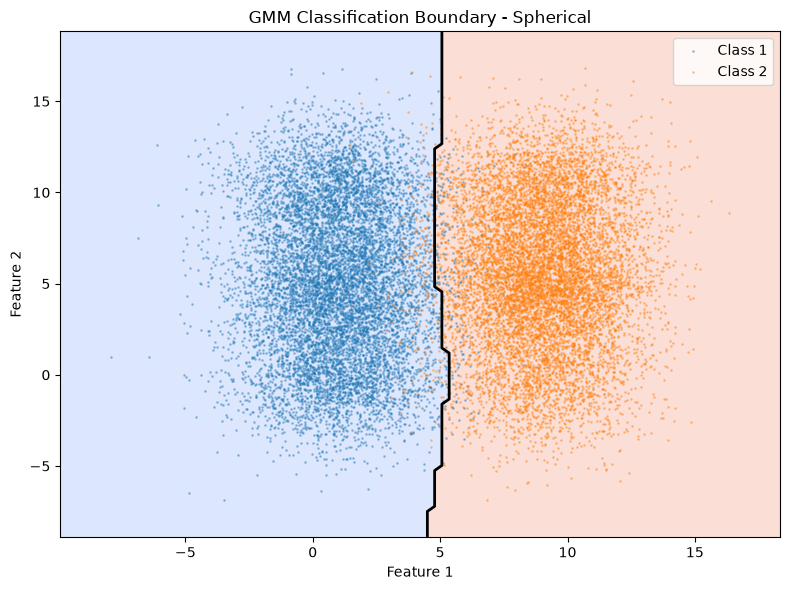

Saved: GMM_Images/spherical_classification_boundary.png


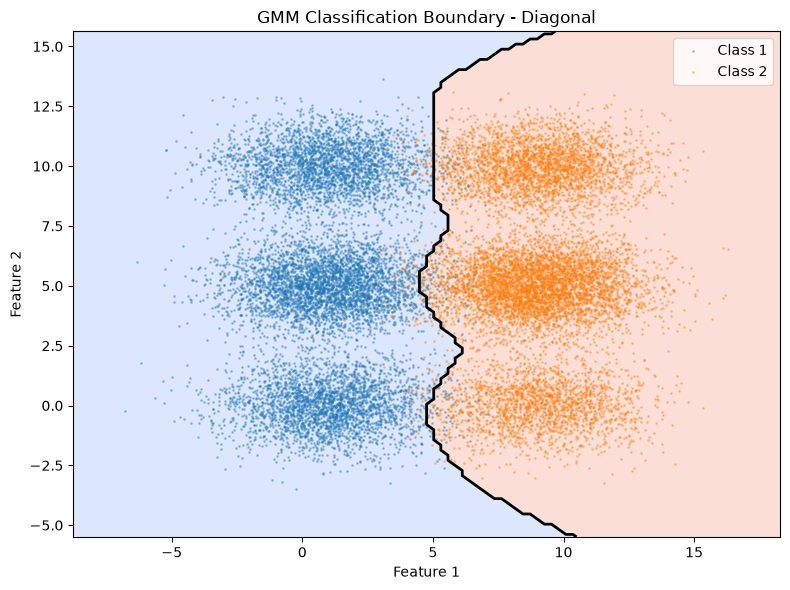

Saved: GMM_Images/diagonal_classification_boundary.png


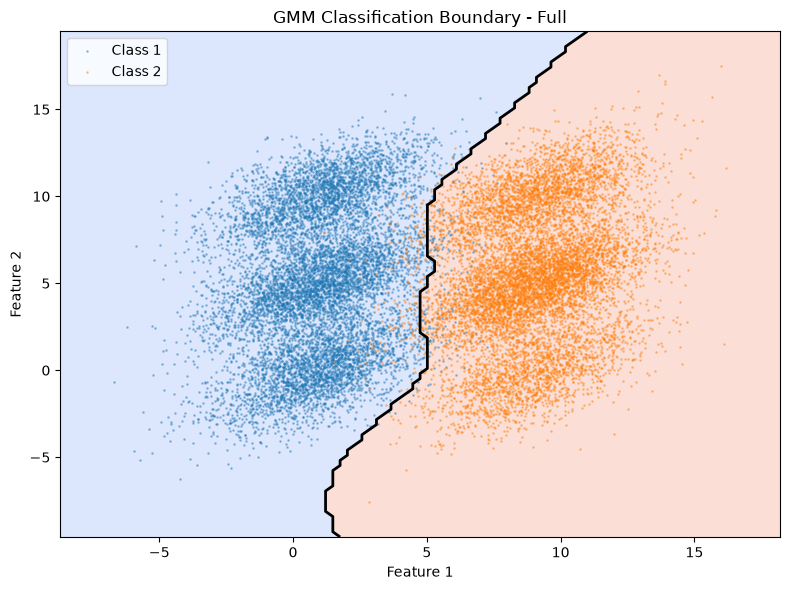

Saved: GMM_Images/full_classification_boundary.png


In [17]:
covariances=[
    ("Spherical",C_spherical,"spherical"),
    ("Diagonal",C_diagonal,"diagonal"),
    ("Full",C_full,"full")
]# Generate data, train models, and plot boundaries
for name,C,cov_type in covariances:
    X1=generate_data(mu1,pi1,C,n)
    X2=generate_data(mu2,pi2,C,n)

    train1,test1=split_data(X1)
    train2,test2=split_data(X2)

    model1=gmm_train(train1,K,100)
    model2=gmm_train(train2,K,100)

    plot_gmm_boundary(X1,X2,model1,model2,name)

In [3]:
# Import libraries
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# dataset path
DATA="TEAM_11"

DIGITS=[1,3,5]
print(" digits - ",DIGITS)
# GMM 
K=3
PCA_COMPONENTS=50
EPS=1e-6

 digits -  [1, 3, 5]


In [4]:
def load_data(split):
    X=[]
    y=[]

    for digit in DIGITS:
        folder=os.path.join(DATA,split,str(digit))

        if not os.path.isdir(folder):
            raise FileNotFoundError("Folder not found: "+folder)

        for file in sorted(os.listdir(folder)):
            if file.lower().endswith((".png",".jpg",".jpeg",".bmp")):
                path=os.path.join(folder,file)

                with Image.open(path) as img:
                    img=img.convert("L").resize((28,28))
                    pixels=np.asarray(img,dtype=np.float64).flatten()/255.0

                X.append(pixels)
                y.append(digit)

    if len(X)==0:
        raise ValueError("No images found in "+split)

    return np.array(X),np.array(y)


X_train,y_train=load_data("train")
X_dev,y_dev=load_data("dev")
X_test,y_test=load_data("test")

print("Training images:",len(X_train))
print("Development images:",len(X_dev))
print("Testing images:",len(X_test))
print("Image dimensions:",X_train.shape[1])

Training images: 14637
Development images: 3657
Testing images: 3037
Image dimensions: 784


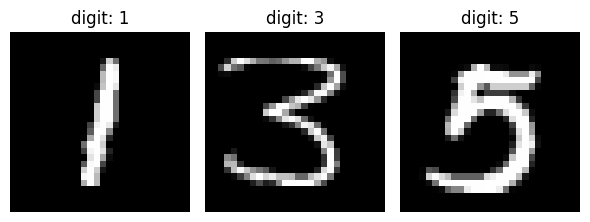

In [5]:
plt.figure(figsize=(6,6))

for i,digit in enumerate(DIGITS):
    idx=np.where(y_train==digit)[0][0]

    plt.subplot(1,3,i+1)
    plt.imshow(X_train[idx].reshape(28,28),cmap="gray")
    plt.title("digit: "+str(digit))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
def fit_pca(X,n):
    mean=X.mean(axis=0)
    Xc=X-mean

    cov=(Xc.T@Xc)/len(Xc)

    values,vectors=np.linalg.eigh(cov)

    idx=np.argsort(values)[::-1][:n]
    components=vectors[:,idx]

    return mean,components,values[idx]


def transform_pca(X,mean,components):
    return (X-mean)@components


print("pca calculation")

pca_mean,components,pca_values=fit_pca(
    X_train,PCA_COMPONENTS
)

X_train_pca=transform_pca(X_train,pca_mean,components)
X_dev_pca=transform_pca(X_dev,pca_mean,components)
X_test_pca=transform_pca(X_test,pca_mean,components)

total_variance=np.var(X_train,axis=0).sum()
retained_variance=pca_values.sum()/total_variance*100

print("Original features:",X_train.shape[1])
print("Reduced features:",X_train_pca.shape[1])
print("Variance retained:",round(retained_variance,2),"%")

pca calculation
Original features: 784
Reduced features: 50
Variance retained: 84.96 %


In [7]:
#gaussian calculation
def log_gaussian(X,means,vars):
    diff=X[:,None,:]-means[None,:,:]

    result=-0.5*np.sum(
        np.log(2*np.pi*vars)[None,:,:]+diff**2/vars[None,:,:],
        axis=2
    )

    return result
def gmm_score(X,model):
    means,vars,weights=model
    logp=log_gaussian(X,means,vars)+np.log(weights+EPS)
    maximum=logp.max(axis=1)
    return maximum+np.log(np.exp(logp-maximum[:,None]).sum(axis=1))

In [8]:
def fit_gmm(X,k=3,max_iter=100,tol=1e-4):
    n,d=X.shape

    if n<k:
        raise ValueError("Training samples must be at least K")

    rng=np.random.default_rng(42)

    means=X[rng.choice(n,k,replace=False)].copy()

    global_var=np.maximum(np.var(X,axis=0),EPS)
    vars=np.tile(global_var,(k,1))

    weights=np.ones(k)/k
    previous_log_likelihood=None

    for iteration in range(max_iter):

        # E-step
        logp=log_gaussian(X,means,vars)+np.log(weights+EPS)

        maximum=logp.max(axis=1,keepdims=True)
        shifted=np.exp(logp-maximum)

        responsibilities=shifted/np.maximum(
            shifted.sum(axis=1,keepdims=True),EPS
        )

        current_log_likelihood=np.sum(
            maximum[:,0]+np.log(
                np.maximum(shifted.sum(axis=1),EPS)
            )
        )

        # M-step
        nk=responsibilities.sum(axis=0)+EPS

        weights=nk/n
        means=(responsibilities.T@X)/nk[:,None]

        for j in range(k):
            diff=X-means[j]

            vars[j]=np.sum(
                responsibilities[:,j,None]*diff**2,
                axis=0
            )/nk[j]

        vars=np.maximum(vars,EPS)
        weights=weights/weights.sum()

        # Check convergence
        if previous_log_likelihood is not None:
            change=abs(
                current_log_likelihood-previous_log_likelihood
            )

            if change<tol:
                print("EM converged at iteration",iteration+1)
                break

        previous_log_likelihood=current_log_likelihood

    return means,vars,weights

In [9]:
#gmm log-likelihood
models={}

for digit in DIGITS:

    print("Training GMM for digit",digit)

    X_digit=X_train_pca[y_train==digit]

    models[digit]=fit_gmm(X_digit,K)

    print("Training completed for digit",digit)

Training GMM for digit 1
Training completed for digit 1
Training GMM for digit 3
EM converged at iteration 64
Training completed for digit 3
Training GMM for digit 5
Training completed for digit 5


In [10]:
dev_scores=np.column_stack([
    gmm_score(X_dev_pca,models[digit])
    for digit in DIGITS
])

dev_predicted=np.array(DIGITS)[np.argmax(dev_scores,axis=1)]

dev_accuracy=100*np.mean(dev_predicted==y_dev)

print("Development accuracy:",round(dev_accuracy,2),"%")
print("Development correct:",np.sum(dev_predicted==y_dev))
print("Development incorrect :",np.sum(dev_predicted!=y_dev))

Development accuracy: 95.76 %
Development correct: 3502
Development incorrect : 155


In [11]:
print("classifying test images")

scores=np.column_stack([
    gmm_score(X_test_pca,models[digit])
    for digit in DIGITS
])

predicted=np.array(DIGITS)[np.argmax(scores,axis=1)]

accuracy=100*np.mean(predicted==y_test)

print("test Accuracy:",round(accuracy,2),"%")

classifying test images
test Accuracy: 96.31 %


In [12]:
def confusion_matrix_manual(actual,predicted):
    cm=np.zeros((len(DIGITS),len(DIGITS)),dtype=int)

    for a,p in zip(actual,predicted):
        i=DIGITS.index(a)
        j=DIGITS.index(p)
        cm[i,j]+=1

    return cm


cm=confusion_matrix_manual(y_test,predicted)

print("Digit order:",DIGITS)
print("Rows = actual digits")
print("Columns = predicted digits")
print("\nConfusion Matrix:")
print(cm)

Digit order: [1, 3, 5]
Rows = actual digits
Columns = predicted digits

Confusion Matrix:
[[1108   10   17]
 [   1  961   48]
 [   0   36  856]]


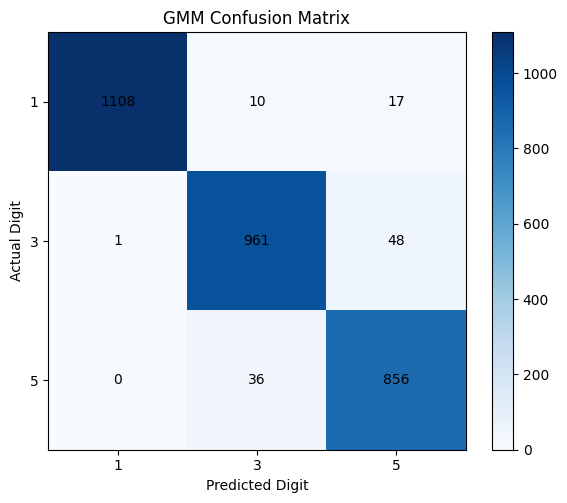

In [13]:
plt.figure(figsize=(6,5))

plt.imshow(cm,cmap="Blues")
plt.colorbar()

plt.xticks(range(len(DIGITS)),DIGITS)
plt.yticks(range(len(DIGITS)),DIGITS)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("GMM Confusion Matrix")

for i in range(len(DIGITS)):
    for j in range(len(DIGITS)):
        plt.text(j,i,str(cm[i,j]),ha="center",va="center")

plt.tight_layout()
plt.show()

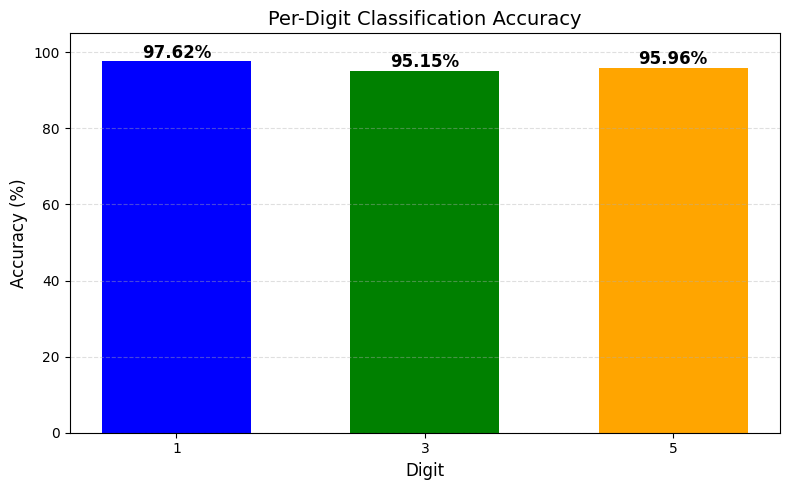

In [ ]:
# Cell 10: Per-digit accuracy bar chart

digits=[]
accuracies=[]

for i,digit in enumerate(DIGITS):
    total=cm[i].sum()
    correct=cm[i,i]
    accuracy=100*correct/max(total,1)
    digits.append(str(digit))
    accuracies.append(accuracy)

# Create bar chart
colors=["blue","green","orange"]

plt.figure(figsize=(8,5))
bars=plt.bar(digits,accuracies,color=colors,width=0.6)

# Display accuracy values above bars
for bar,accuracy in zip(bars,accuracies):
    plt.text(bar.get_x()+bar.get_width()/2,bar.get_height()+1,
             f"{accuracy:.2f}%",ha="center",fontsize=12,fontweight="bold")

plt.title("Per-Digit Classification Accuracy",fontsize=14)
plt.xlabel("Digit",fontsize=12)
plt.ylabel("Accuracy (%)",fontsize=12)
plt.ylim(0,105)
plt.grid(axis="y",linestyle="--",alpha=0.4)
plt.tight_layout()
plt.show()

Total misclassified images: 112

Actual class 1: 27 misclassified images

Actual class 3: 49 misclassified images

Actual class 5: 36 misclassified images


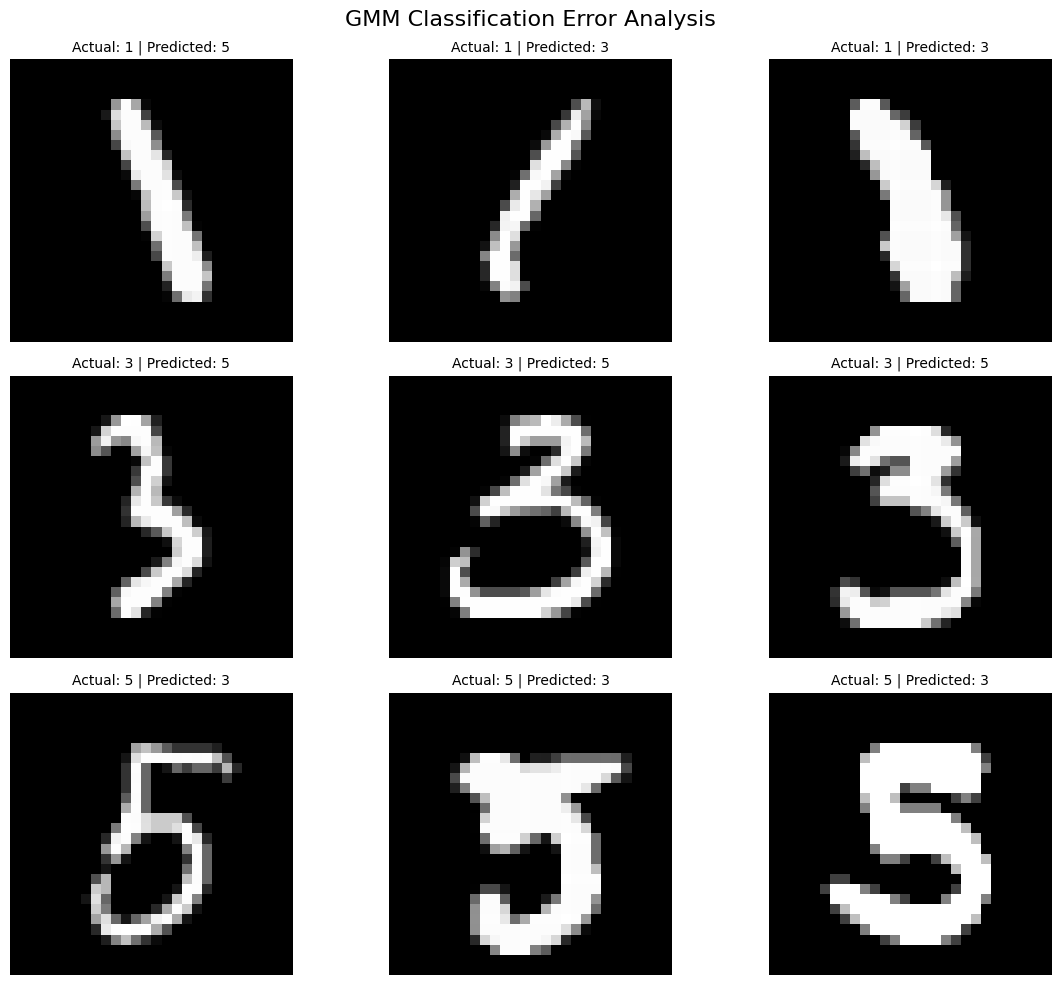

In [16]:

import numpy as np
import matplotlib.pyplot as plt

# Step 1: Find all misclassified images
wrong_indices = np.where(predicted != y_test)[0]

print("Total misclassified images:", len(wrong_indices))

# Step 2: Select actual classes
actual_classes = [1, 3, 5]

# Step 3: Create a 3 x 3 visualization
plt.figure(figsize=(12, 10))

for row, cls in enumerate(actual_classes):

    # Find misclassified images for the current actual class
    class_wrong_indices = np.where(
        (y_test == cls) & (predicted != y_test)
    )[0]

    print(
        f"\nActual class {cls}: "
        f"{len(class_wrong_indices)} misclassified images"
    )

    # Display 3 examples
    for col in range(3):

        plt.subplot(3, 3, row * 3 + col + 1)

        if col < len(class_wrong_indices):

            idx = class_wrong_indices[col]

            actual = y_test[idx]
            pred = predicted[idx]

            # Display image
            plt.imshow(
                X_test[idx].reshape(28, 28),
                cmap="gray"
            )

            plt.title(
                f"Actual: {actual} | Predicted: {pred}",
                fontsize=10
            )

        else:
            plt.text(
                0.5, 0.5,
                "No more examples",
                ha="center",
                va="center"
            )

        plt.axis("off")

# Step 4: Add main title
plt.suptitle(
    "GMM Classification Error Analysis",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [17]:
print("GMM Classification Error Analysis")

for actual in DIGITS:
    for pred in DIGITS:

        if actual==pred:
            continue

        count=np.sum((y_test==actual)&(predicted==pred))

        if count>0:
            print(
                "Actual:",actual,
                "Predicted:",pred,
                "Count:",count
            )

print("\nLog-Likelihood Analysis")

for idx in wrong_indices[:12]:

    actual=y_test[idx]
    pred=predicted[idx]

    actual_score=scores[idx,DIGITS.index(actual)]
    predicted_score=scores[idx,DIGITS.index(pred)]

    print(
        "Actual:",actual,
        "Predicted:",pred,
        "Actual LL:",round(actual_score,3),
        "Predicted LL:",round(predicted_score,3),
        "Difference:",round(predicted_score-actual_score,3)
    )

GMM Classification Error Analysis
Actual: 1 Predicted: 3 Count: 10
Actual: 1 Predicted: 5 Count: 17
Actual: 3 Predicted: 1 Count: 1
Actual: 3 Predicted: 5 Count: 48
Actual: 5 Predicted: 3 Count: 36

Log-Likelihood Analysis
Actual: 1 Predicted: 5 Actual LL: -61.177 Predicted LL: -57.975 Difference: 3.202
Actual: 1 Predicted: 3 Actual LL: -48.012 Predicted LL: -47.715 Difference: 0.298
Actual: 1 Predicted: 3 Actual LL: -85.838 Predicted LL: -68.13 Difference: 17.708
Actual: 1 Predicted: 3 Actual LL: -48.872 Predicted LL: -42.806 Difference: 6.066
Actual: 1 Predicted: 5 Actual LL: -88.042 Predicted LL: -61.551 Difference: 26.492
Actual: 1 Predicted: 5 Actual LL: -69.065 Predicted LL: -53.935 Difference: 15.13
Actual: 1 Predicted: 5 Actual LL: -66.955 Predicted LL: -60.75 Difference: 6.204
Actual: 1 Predicted: 5 Actual LL: -57.911 Predicted LL: -50.832 Difference: 7.079
Actual: 1 Predicted: 3 Actual LL: -107.324 Predicted LL: -63.444 Difference: 43.879
Actual: 1 Predicted: 5 Actual LL: -11

EM converged at iteration 45
Predicted regions:
(array([0, 1, 2], dtype=int64), array([10004, 19775, 10221], dtype=int64))


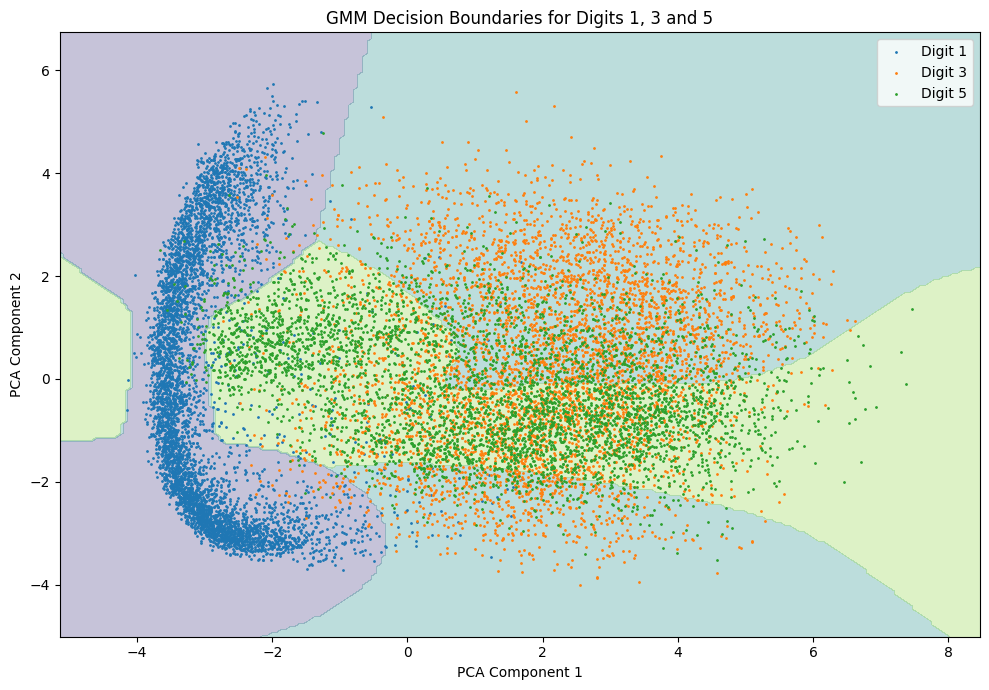

In [18]:

# GMM Decision Boundaries (2D Visualization)

# Use first two PCA components
X_2d=X_train_pca[:,:2]
y=y_train

# Train separate 2D GMM models for visualization
models_2d={}

for d in DIGITS:
    X_digit=X_2d[y==d]
    models_2d[d]=fit_gmm(X_digit,K)

# Create grid
x_min,x_max=X_2d[:,0].min()-1,X_2d[:,0].max()+1
y_min,y_max=X_2d[:,1].min()-1,X_2d[:,1].max()+1

xx,yy=np.meshgrid(
    np.linspace(x_min,x_max,200),
    np.linspace(y_min,y_max,200)
)

grid=np.column_stack((xx.ravel(),yy.ravel()))

# Calculate scores
boundary_scores=np.column_stack([
    gmm_score(grid,models_2d[d]) for d in DIGITS
])

# Predict regions
Z=np.argmax(boundary_scores,axis=1)
Z=Z.reshape(xx.shape)

print("Predicted regions:")
print(np.unique(Z,return_counts=True))

# Plot
plt.figure(figsize=(10,7))

plt.contourf(
    xx,yy,Z,
    levels=[-0.5,0.5,1.5,2.5],
    alpha=0.3,
    cmap="viridis"
)

for d in DIGITS:
    plt.scatter(
        X_2d[y==d,0],
        X_2d[y==d,1],
        label=f"Digit {d}",
        s=1
    )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("GMM Decision Boundaries for Digits 1, 3 and 5")
plt.legend()
plt.tight_layout()
plt.show()


In [19]:
print("FINAL CLASSIFICATION RESULTS")

print("Team: 11")
print("Digits:",DIGITS)

print("Training images:",len(X_train))
print("Development images:",len(X_dev))
print("Testing images:",len(X_test))

print("Original features:",X_train.shape[1])
print("PCA components:",PCA_COMPONENTS)
print("GMM components:",K)
print("\n")
print("Development accuracy:",round(dev_accuracy,2),"%")
print("Test accuracy:",round(accuracy,2),"%")

print("Correct predictions:",np.sum(predicted==y_test))
print("Incorrect predictions:",np.sum(predicted!=y_test))

FINAL CLASSIFICATION RESULTS
Team: 11
Digits: [1, 3, 5]
Training images: 14637
Development images: 3657
Testing images: 3037
Original features: 784
PCA components: 50
GMM components: 3


Development accuracy: 95.76 %
Test accuracy: 95.96 %
Correct predictions: 2925
Incorrect predictions: 112


In [20]:
test_scores=np.column_stack([
    gmm_score(X_test_pca,models[d]) for d in DIGITS
])

test_predictions=np.array(DIGITS)[np.argmax(test_scores,axis=1)]

print("Test predictions:")
print(np.unique(test_predictions,return_counts=True))

Test predictions:
(array([1, 3, 5]), array([1109, 1007,  921], dtype=int64))
